## Wayfair ecommerce data analysis 

### Author: M R Shaheedullah, GitHub Copilot off (one plotting cell from Gemini)

### Summary of Brief

1. Load and clean files
2. Work out how to calculate revenue
3. Plot revenue over time (by month)
4. Break revenue down by product category.  Find the best selling products.
5. Look at how the category mix changes through the year.
6. Which categories are in orders that have been returned or cancelled?  Which have the best order value?. 

## 1. Load and clean files

In [47]:
# import packages
import pandas as pd
from data_profiling import ProfileReport
import datetime as dt
import matplotlib.pyplot as plt
import seaborn as sns

In [48]:
# import data
customers = pd.read_csv(r"C:\Users\conif\Documents\Projects\Data-Career-School\ecommerce-sales-analysis-datasets\ecommerce-sales-analysis\data\customers.csv", parse_dates=['signup_date'])


In [49]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3600 entries, 0 to 3599
Data columns (total 4 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   customer_id          3600 non-null   int64         
 1   signup_date          3600 non-null   datetime64[ns]
 2   state                3600 non-null   object        
 3   acquisition_channel  3600 non-null   object        
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 112.6+ KB


In [50]:
customers

,customer_id,signup_date,state,acquisition_channel
0,1,2024-09-13,CO,organic_search
1,2,2025-10-21,IL,paid_search
2,3,2025-01-17,AZ,referral
3,4,2024-06-23,FL,paid_social
4,5,2025-04-08,IL,paid_social
...,...,...,...,...
3595,3596,2025-11-14,LA,referral
3596,3597,2025-05-27,WA,paid_search
3597,3598,2024-06-03,CA,paid_search
3598,3599,2025-08-23,LA,organic_search


In [51]:
c_dupes = customers.duplicated()
print(c_dupes.sum())

0


In [52]:
products = pd.read_csv(r"C:\Users\conif\Documents\Projects\Data-Career-School\ecommerce-sales-analysis-datasets\ecommerce-sales-analysis\data\products.csv")

In [53]:
products.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   product_id    90 non-null     int64  
 1   product_name  90 non-null     object 
 2   category      90 non-null     object 
 3   list_price    90 non-null     float64
 4   unit_cost     90 non-null     float64
dtypes: float64(2), int64(1), object(2)
memory usage: 3.6+ KB


In [54]:
p_dupes = products.duplicated()
print(p_dupes.sum())

0


In [55]:
products['category'] = products['category'].str.strip().str.capitalize()

In [56]:
products

,product_id,product_name,category,list_price,unit_cost
0,1001,Brass Chef Knife,Kitchen,61.99,38.13
1,1002,Walnut Cutting Board,Kitchen,138.99,74.76
2,1003,Matte Black Dutch Oven,Kitchen,22.99,13.50
3,1004,Classic Skillet,Kitchen,75.99,39.86
4,1005,Linen Mixing Bowl Set,Kitchen,79.99,41.11
...,...,...,...,...,...
85,1086,Modern Under Bed Bin,Storage,97.99,43.62
86,1087,Cotton Pantry Container Set,Storage,45.99,20.30
87,1088,Coastal Coat Rack,Storage,20.99,12.03
88,1089,Modern Floating Shelf,Storage,53.99,24.22


In [57]:
orders = pd.read_csv(r"C:\Users\conif\Documents\Projects\Data-Career-School\ecommerce-sales-analysis-datasets\ecommerce-sales-analysis\data\orders.csv", parse_dates=['order_date'])

In [58]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9245 entries, 0 to 9244
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        9245 non-null   int64         
 1   customer_id     9245 non-null   int64         
 2   order_date      9245 non-null   datetime64[ns]
 3   status          9245 non-null   object        
 4   payment_method  9245 non-null   object        
 5   discount_code   1411 non-null   object        
 6   shipping_fee    9245 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(2), object(3)
memory usage: 505.7+ KB


In [59]:
orders.isna().sum()

order_id             0
customer_id          0
order_date           0
status               0
payment_method       0
discount_code     7834
shipping_fee         0
dtype: int64

In [60]:
o_dupes = orders.duplicated()
print(o_dupes.sum())

38


In [61]:
orders

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
0,100001,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95
1,100002,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00
2,100003,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00
3,100004,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00
4,100005,3452,2024-01-01 17:44:03,completed,gift_card,NaN,0.00
...,...,...,...,...,...,...,...
9240,109203,3499,2025-12-31 16:50:18,completed,credit_card,HOLIDAY20,6.95
9241,109204,3410,2025-12-31 17:40:58,completed,credit_card,HOLIDAY20,0.00
9242,109205,2911,2025-12-31 18:21:51,completed,credit_card,NaN,0.00
9243,109206,1157,2025-12-31 21:38:59,completed,credit_card,NaN,6.95


In [62]:
# view duplicates
orders[orders.duplicated(keep=False)]

,order_id,customer_id,order_date,status,payment_method,discount_code,shipping_fee
47,100048,3320,2024-01-06 16:37:36,completed,credit_card,NaN,6.95
130,107012,870,2025-08-12 10:39:49,completed,apple_pay,NaN,0.00
303,100303,853,2024-02-03 08:33:22,completed,apple_pay,NaN,0.00
310,106199,3072,2025-06-09 23:50:03,completed,credit_card,NaN,6.95
479,104695,443,2025-02-14 11:56:23,completed,credit_card,NaN,0.00
...,...,...,...,...,...,...,...
8737,107493,1664,2025-09-21 23:42:50,completed,apple_pay,NaN,6.95
9032,102517,1254,2024-08-28 20:08:41,completed,paypal,NaN,0.00
9104,109068,1981,2025-12-20 13:27:25,completed,credit_card,HOLIDAY20,6.95
9122,108138,1241,2025-11-07 12:15:41,returned,gift_card,NaN,0.00


In [63]:
# drop duplicates
orders = orders.drop_duplicates()

In [64]:
orders.info()

<class 'pandas.core.frame.DataFrame'>
Index: 9207 entries, 0 to 9244
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        9207 non-null   int64         
 1   customer_id     9207 non-null   int64         
 2   order_date      9207 non-null   datetime64[ns]
 3   status          9207 non-null   object        
 4   payment_method  9207 non-null   object        
 5   discount_code   1405 non-null   object        
 6   shipping_fee    9207 non-null   float64       
dtypes: datetime64[ns](1), float64(1), int64(2), object(3)
memory usage: 575.4+ KB


In [65]:
order_items = pd.read_csv(r"C:\Users\conif\Documents\Projects\Data-Career-School\ecommerce-sales-analysis-datasets\ecommerce-sales-analysis\data\order_items.csv")

In [66]:
order_items

,order_id,product_id,quantity,unit_price,discount_amount
0,100001,1031,1,38.99,0.00
1,100002,1087,1,45.99,0.00
2,100002,1072,1,141.99,0.00
3,100003,1048,1,139.99,0.00
4,100004,1083,1,19.99,2.00
...,...,...,...,...,...
15603,109204,1070,1,129.14,25.83
15604,109205,1072,2,149.09,0.00
15605,109206,1071,1,10.49,0.00
15606,109207,1023,2,142.79,57.12


In [67]:
order_items.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15608 entries, 0 to 15607
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         15608 non-null  int64  
 1   product_id       15608 non-null  int64  
 2   quantity         15608 non-null  int64  
 3   unit_price       15409 non-null  float64
 4   discount_amount  15608 non-null  float64
dtypes: float64(2), int64(3)
memory usage: 609.8 KB


In [68]:
oi_dupes = order_items.duplicated()
print(oi_dupes.sum())

0


## 2. Calculation of revenue

Only completed orders (from status column) in orders table will count as revenue.  Order figures are in order_items table.  Hence we need to left join order_items to orders.
The following calculation will occur by row;

total price = (quantity * unit price) - discount

We need to group by order_id to aggregate the total price.  We then have multiple shipping fee per order ( all the same), where it exists.  This is solved by taking the first instance of shipping fee per order.  (This will be the same for order date).

The calculation of revenue for each order will be as follows;

revenue = total price - shipping fee


In [69]:
full_orders = pd.merge(order_items, orders, left_on='order_id', right_on='order_id', how='left')

In [70]:
completed_orders = full_orders[full_orders['status']=='completed'].copy()

In [71]:
completed_orders

,order_id,product_id,quantity,unit_price,discount_amount,customer_id,order_date,status,payment_method,discount_code,shipping_fee
0,100001,1031,1,38.99,0.00,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95
1,100002,1087,1,45.99,0.00,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00
2,100002,1072,1,141.99,0.00,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00
3,100003,1048,1,139.99,0.00,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00
4,100004,1083,1,19.99,2.00,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00
...,...,...,...,...,...,...,...,...,...,...,...
15603,109204,1070,1,129.14,25.83,3410,2025-12-31 17:40:58,completed,credit_card,HOLIDAY20,0.00
15604,109205,1072,2,149.09,0.00,2911,2025-12-31 18:21:51,completed,credit_card,NaN,0.00
15605,109206,1071,1,10.49,0.00,1157,2025-12-31 21:38:59,completed,credit_card,NaN,6.95
15606,109207,1023,2,142.79,57.12,2208,2025-12-31 23:23:29,completed,paypal,HOLIDAY20,0.00


In [72]:
completed_orders['total_price'] = (completed_orders['quantity'] * completed_orders['unit_price']) - completed_orders['discount_amount']

In [73]:
completed_orders

,order_id,product_id,quantity,unit_price,discount_amount,customer_id,order_date,status,payment_method,discount_code,shipping_fee,total_price
0,100001,1031,1,38.99,0.00,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95,38.99
1,100002,1087,1,45.99,0.00,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,45.99
2,100002,1072,1,141.99,0.00,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,141.99
3,100003,1048,1,139.99,0.00,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00,139.99
4,100004,1083,1,19.99,2.00,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00,17.99
...,...,...,...,...,...,...,...,...,...,...,...,...
15603,109204,1070,1,129.14,25.83,3410,2025-12-31 17:40:58,completed,credit_card,HOLIDAY20,0.00,103.31
15604,109205,1072,2,149.09,0.00,2911,2025-12-31 18:21:51,completed,credit_card,NaN,0.00,298.18
15605,109206,1071,1,10.49,0.00,1157,2025-12-31 21:38:59,completed,credit_card,NaN,6.95,10.49
15606,109207,1023,2,142.79,57.12,2208,2025-12-31 23:23:29,completed,paypal,HOLIDAY20,0.00,228.46


Group by and aggregate - sum(total_price),  first(shipping_fee), first(order_date) 

In [74]:
grouped = completed_orders.groupby('order_id').agg({'total_price' : 'sum' , 'shipping_fee':'first' , 'order_date' : 'first'})

In [75]:
grouped

,total_price,shipping_fee,order_date
order_id,,,
100001,38.99,6.95,2024-01-01 09:24:45
100002,187.98,0.00,2024-01-01 10:37:49
100003,139.99,0.00,2024-01-01 10:59:09
100004,188.97,0.00,2024-01-01 12:48:34
100005,124.99,0.00,2024-01-01 17:44:03
...,...,...,...
109203,42.83,6.95,2025-12-31 16:50:18
109204,198.22,0.00,2025-12-31 17:40:58
109205,298.18,0.00,2025-12-31 18:21:51


In [76]:
grouped['revenue'] = round((grouped['total_price'] - grouped['shipping_fee']), 2)

In [77]:
grouped

,total_price,shipping_fee,order_date,revenue
order_id,,,,
100001,38.99,6.95,2024-01-01 09:24:45,32.04
100002,187.98,0.00,2024-01-01 10:37:49,187.98
100003,139.99,0.00,2024-01-01 10:59:09,139.99
100004,188.97,0.00,2024-01-01 12:48:34,188.97
100005,124.99,0.00,2024-01-01 17:44:03,124.99
...,...,...,...,...
109203,42.83,6.95,2025-12-31 16:50:18,35.88
109204,198.22,0.00,2025-12-31 17:40:58,198.22
109205,298.18,0.00,2025-12-31 18:21:51,298.18


In [78]:
# grouped['order_date'] = pd.to_datetime(grouped['order_date']).dt.date
# does not work with dt.year, need datetime

In [79]:
order_info = grouped[['order_date', 'revenue']].copy()

In [80]:
order_info['year'] = order_info['order_date'].dt.year
order_info['month'] = order_info['order_date'].dt.month

### 3. Plot revenue versus time

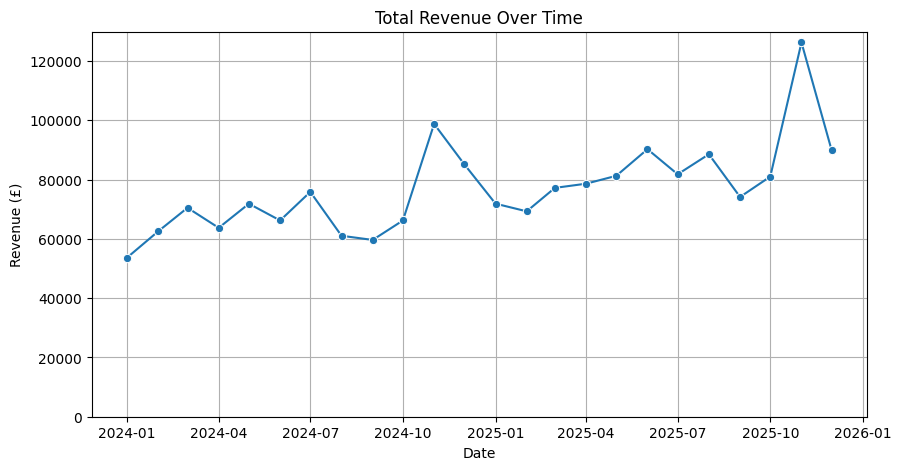

In [81]:
# this cell from Gemini
# 1. Group by year and month to get the total revenue per month
monthly_revenue = order_info.groupby(['year', 'month'])['revenue'].sum().reset_index()

# 2. Combine year and month into a single datetime column for smooth plotting
monthly_revenue['date'] = pd.to_datetime(
    monthly_revenue['year'].astype(str) + '-' + monthly_revenue['month'].astype(str) + '-01'
)

# 3. Plot using Seaborn
plt.figure(figsize=(10, 5))
sns.lineplot(data=monthly_revenue, x='date', y='revenue', marker='o')

plt.title('Total Revenue Over Time')
plt.xlabel('Date')
plt.ylabel('Revenue (£)')
plt.ylim(bottom=0) 
plt.grid(True)
plt.show()


## 4. Break revenue down by product category.  Find the best selling products.

For this analysis we need to go back to the full_orders dataframe, after filtering for completed orders.  Then we will join completed_orders on to products to get product info.

In [82]:
orders_with_products = pd.merge(completed_orders, products, how='left')

In [83]:
orders_with_products

,order_id,product_id,quantity,unit_price,discount_amount,customer_id,order_date,status,payment_method,discount_code,shipping_fee,total_price,product_name,category,list_price,unit_cost
0,100001,1031,1,38.99,0.00,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95,38.99,Stoneware Soap Dispenser,Bath,38.99,20.19
1,100002,1087,1,45.99,0.00,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,45.99,Cotton Pantry Container Set,Storage,45.99,20.30
2,100002,1072,1,141.99,0.00,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,141.99,Coastal Picture Frame Set,Decor,141.99,62.78
3,100003,1048,1,139.99,0.00,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00,139.99,Linen Loveseat,Furniture,139.99,71.41
4,100004,1083,1,19.99,2.00,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00,17.99,Velvet Drawer Organizer,Storage,19.99,9.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14278,109204,1070,1,129.14,25.83,3410,2025-12-31 17:40:58,completed,credit_card,HOLIDAY20,0.00,103.31,Stoneware Wall Mirror,Decor,122.99,51.74
14279,109205,1072,2,149.09,0.00,2911,2025-12-31 18:21:51,completed,credit_card,NaN,0.00,298.18,Coastal Picture Frame Set,Decor,141.99,62.78
14280,109206,1071,1,10.49,0.00,1157,2025-12-31 21:38:59,completed,credit_card,NaN,6.95,10.49,Oak Vase,Decor,9.99,5.84
14281,109207,1023,2,142.79,57.12,2208,2025-12-31 23:23:29,completed,paypal,HOLIDAY20,0.00,228.46,Linen Pillowcase Set,Bedding,135.99,60.49


To calculate revenue per category, we will firstly calculate a unit_revenue, and as shipping fee and discount are per order not per item, these will not be taken into account.  We will then group by category and sum unit_revenue

In [84]:
orders_with_products['unit_revenue'] = orders_with_products['list_price'] - orders_with_products['unit_cost']

In [85]:
revenue_per_category = round(orders_with_products.groupby('category')['unit_revenue'].sum(), 2)

In [86]:
revenue_per_category = revenue_per_category.reset_index()

In [87]:
revenue_per_category = revenue_per_category.sort_values(by='unit_revenue', ascending=False)

In [88]:
revenue_per_category

,category,unit_revenue
3,Furniture,147200.45
2,Decor,113711.53
1,Bedding,107409.62
4,Kitchen,105613.67
6,Outdoor,98361.50
5,Lighting,88932.30
7,Storage,61419.74
0,Bath,40611.93


Plot data in barchart

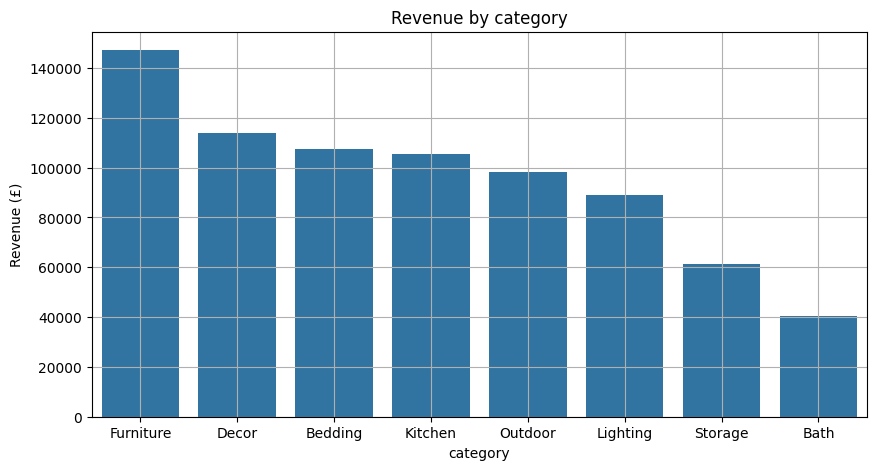

In [89]:
# 3. Plot using Seaborn
plt.figure(figsize=(10, 5))
sns.barplot(data=revenue_per_category, x='category', y='unit_revenue')

plt.title('Revenue by category')
plt.xlabel('category')
plt.ylabel('Revenue (£)')
plt.ylim(bottom=0) 
plt.grid(True)
plt.show()

Find the best selling products

In [43]:
orders_with_products

,order_id,product_id,quantity,unit_price,discount_amount,customer_id,order_date,status,payment_method,discount_code,shipping_fee,total_price,product_name,category,list_price,unit_cost
0,100001,1031,1,38.99,0.00,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95,38.99,Stoneware Soap Dispenser,Bath,38.99,20.19
1,100002,1087,1,45.99,0.00,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,45.99,Cotton Pantry Container Set,Storage,45.99,20.30
2,100002,1072,1,141.99,0.00,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,141.99,Coastal Picture Frame Set,Decor,141.99,62.78
3,100003,1048,1,139.99,0.00,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00,139.99,Linen Loveseat,Furniture,139.99,71.41
4,100004,1083,1,19.99,2.00,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00,17.99,Velvet Drawer Organizer,Storage,19.99,9.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
14278,109204,1070,1,129.14,25.83,3410,2025-12-31 17:40:58,completed,credit_card,HOLIDAY20,0.00,103.31,Stoneware Wall Mirror,Decor,122.99,51.74
14279,109205,1072,2,149.09,0.00,2911,2025-12-31 18:21:51,completed,credit_card,NaN,0.00,298.18,Coastal Picture Frame Set,Decor,141.99,62.78
14280,109206,1071,1,10.49,0.00,1157,2025-12-31 21:38:59,completed,credit_card,NaN,6.95,10.49,Oak Vase,Decor,9.99,5.84
14281,109207,1023,2,142.79,57.12,2208,2025-12-31 23:23:29,completed,paypal,HOLIDAY20,0.00,228.46,Linen Pillowcase Set,Bedding,135.99,60.49


In [44]:
orders_with_products['product_id'].nunique()

90

In [45]:
orders_with_products['product_name'].nunique()

90

Note: number of distinct product_id matches number of distinct product names, indicating clean data for these columns

### 5. Look at how the category mix changes through the year.

We need to plot a stacked bar chart of categories through each year, by revenue

In [103]:
# acquire year and month in this df
orders_with_products['year'] = orders_with_products['order_date'].dt.year
orders_with_products['month'] = orders_with_products['order_date'].dt.month
# filter for 2024
df_2024 = orders_with_products[orders_with_products['year']==2024]
# filter for 2025
df_2025 = orders_with_products[orders_with_products['year']==2025]

In [104]:
# prepare df for plot using group by
df_2024 = df_2024.groupby(['month', 'category'])['list_price'].sum().unstack()
df_2025 = df_2025.groupby(['month', 'category'])['list_price'].sum().unstack()


In [105]:
df_2024

category,Bath,Bedding,Decor,Furniture,Kitchen,Lighting,Outdoor,Storage
month,,,,,,,,
1,3191.42,7808.34,6657.11,6623.77,7418.01,6445.54,1674.89,3606.49
2,3396.35,7528.39,7546.04,10662.69,9023.76,7882.50,2744.84,3448.35
3,3741.32,8331.30,7071.15,16021.59,7815.93,7145.56,6566.57,4240.37
4,2551.55,6244.41,6752.11,12251.68,6427.19,6527.61,11927.17,3391.43
5,3231.43,7949.31,6653.18,12707.60,6674.16,8031.53,13928.92,3359.47
6,3083.47,5898.54,5845.29,3961.86,8434.96,6852.60,18116.86,2765.45
7,3224.42,9282.25,5877.23,12201.65,8049.99,5338.66,17317.01,4142.36
8,2149.59,7354.40,6335.19,9676.72,7808.00,7249.53,8556.38,3432.49
9,3359.44,8838.29,6343.19,9761.72,6694.09,6168.60,6621.65,3211.48


<Figure size 1500x1000 with 0 Axes>

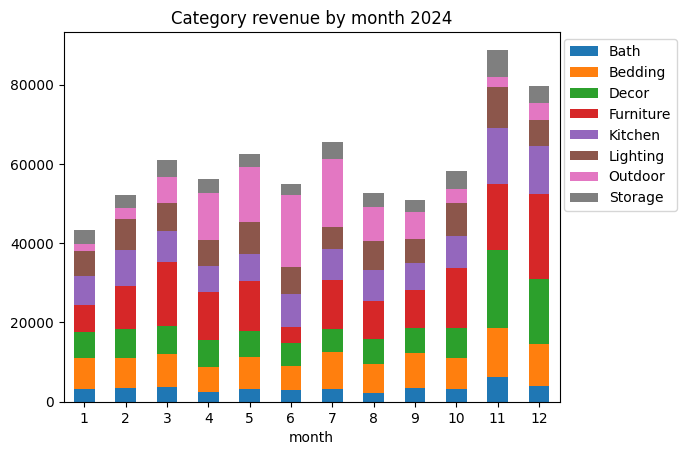

In [106]:
plt.figure(figsize=(15, 10))
df_2024.plot(kind='bar', stacked=True)

#title and rotate the x-axis labels to be horizontal.
plt.legend(bbox_to_anchor=(1.25, 1), loc='upper right')
plt.title('Category revenue by month 2024')
plt.xticks(rotation=0, ha='center')
plt.show()

<Figure size 1500x1000 with 0 Axes>

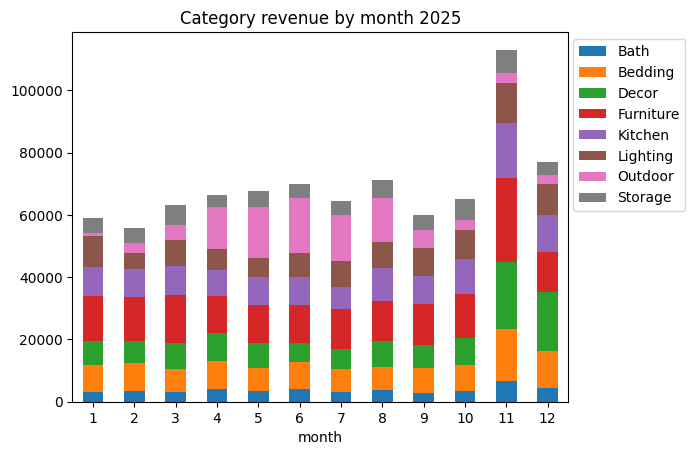

In [107]:
plt.figure(figsize=(15, 10))
df_2025.plot(kind='bar', stacked=True)

#title and rotate the x-axis labels to be horizontal.
plt.legend(bbox_to_anchor=(1.25, 1), loc='upper right')
plt.title('Category revenue by month 2025')
plt.xticks(rotation=0, ha='center')
plt.show()

6. Which categories are in orders that have been returned or cancelled?  Which have the best order value?. 

orders_with_products is for completed orders only.  Hence we will go back to full_orders and join that with products.

In [108]:
full_orders_with_products = pd.merge(full_orders, products, how='left')

In [109]:
full_orders_with_products

,order_id,product_id,quantity,unit_price,discount_amount,customer_id,order_date,status,payment_method,discount_code,shipping_fee,product_name,category,list_price,unit_cost
0,100001,1031,1,38.99,0.00,1530,2024-01-01 09:24:45,completed,credit_card,NaN,6.95,Stoneware Soap Dispenser,Bath,38.99,20.19
1,100002,1087,1,45.99,0.00,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,Cotton Pantry Container Set,Storage,45.99,20.30
2,100002,1072,1,141.99,0.00,3531,2024-01-01 10:37:49,completed,credit_card,NaN,0.00,Coastal Picture Frame Set,Decor,141.99,62.78
3,100003,1048,1,139.99,0.00,840,2024-01-01 10:59:09,completed,credit_card,NaN,0.00,Linen Loveseat,Furniture,139.99,71.41
4,100004,1083,1,19.99,2.00,725,2024-01-01 12:48:34,completed,apple_pay,WELCOME10,0.00,Velvet Drawer Organizer,Storage,19.99,9.51
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15603,109204,1070,1,129.14,25.83,3410,2025-12-31 17:40:58,completed,credit_card,HOLIDAY20,0.00,Stoneware Wall Mirror,Decor,122.99,51.74
15604,109205,1072,2,149.09,0.00,2911,2025-12-31 18:21:51,completed,credit_card,NaN,0.00,Coastal Picture Frame Set,Decor,141.99,62.78
15605,109206,1071,1,10.49,0.00,1157,2025-12-31 21:38:59,completed,credit_card,NaN,6.95,Oak Vase,Decor,9.99,5.84
15606,109207,1023,2,142.79,57.12,2208,2025-12-31 23:23:29,completed,paypal,HOLIDAY20,0.00,Linen Pillowcase Set,Bedding,135.99,60.49


We need to find categories breakdown with number of items that have been returned or canceled.

In [ ]:
# calc returned or canceled items by quantity
ret_or_canceled = full_orders_with_products[['category', 'status']].value_counts().reset_index()

In [111]:
ret_or_canceled = ret_or_canceled[ret_or_canceled['status']!='completed']

In [112]:
ret_or_canceled

,category,status,count
8,Kitchen,returned,139
9,Decor,returned,136
10,Furniture,returned,123
11,Kitchen,canceled,119
12,Decor,canceled,116
13,Bedding,returned,98
14,Bath,canceled,77
15,Storage,returned,76
16,Bath,returned,75
17,Outdoor,returned,69


Calculate number of retuned and canceled as a percentage of total.

In [113]:
# first we must combine the retruned and canceled numbers for each category
ret_or_canceled = ret_or_canceled.groupby('category')['count'].sum().reset_index()

In [114]:
ret_or_canceled

,category,count
0,Bath,152
1,Bedding,160
2,Decor,252
3,Furniture,154
4,Kitchen,258
5,Lighting,87
6,Outdoor,125
7,Storage,137


In [117]:
# now go back and calculate total number of orders for each category
total_num_orders = full_orders_with_products[['category']].groupby('category').value_counts().reset_index(name='full_count')

In [118]:
total_num_orders

,category,full_count
0,Bath,1740
1,Bedding,1932
2,Decor,3073
3,Furniture,1045
4,Kitchen,3195
5,Lighting,1295
6,Outdoor,1476
7,Storage,1852


In [120]:
# merge dataframes
percent_ret_or_canceled = pd.merge(total_num_orders, ret_or_canceled, how='left')

In [121]:
percent_ret_or_canceled

,category,full_count,count
0,Bath,1740,152
1,Bedding,1932,160
2,Decor,3073,252
3,Furniture,1045,154
4,Kitchen,3195,258
5,Lighting,1295,87
6,Outdoor,1476,125
7,Storage,1852,137


In [126]:
percent_ret_or_canceled['percent_r_c'] = round(((percent_ret_or_canceled['count'] / percent_ret_or_canceled['full_count']) * 100), 2)

In [129]:
percent_ret_or_canceled.sort_values(by='percent_r_c', ascending=False)

,category,full_count,count,percent_r_c
3,Furniture,1045,154,14.74
0,Bath,1740,152,8.74
6,Outdoor,1476,125,8.47
1,Bedding,1932,160,8.28
2,Decor,3073,252,8.20
4,Kitchen,3195,258,8.08
7,Storage,1852,137,7.40
5,Lighting,1295,87,6.72
